In [ ]:
from pyscf import gto, scf
import numpy as np
from oracles import *
import scipy as sp
from python_impls.pure_scf import *
from python_impls.cg_scf import *
from python_impls.cbcd_scf import *
from code_in_c.fast_scf import *   # ← add this line

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pgf import FigureCanvasPgf
from cycler import cycler
import awkward as ak
from pprint import pprint
from datetime import datetime
import json
from pathlib import Path
import re

# matplotlib 3.11's usetex PDF backend silently drops minus signs (log-axis
# exponents 10^{-n}, "$-$", etc.) — they show in PNG but not PDF. Route all
# .pdf saves through the pgf backend (typesets via pdflatex) so minuses embed
# correctly. PNG saves still use the default (Agg + usetex).
matplotlib.backend_bases.register_backend("pdf", FigureCanvasPgf)

# --- Match the PRB (REVTeX4-2 reprint, aps/prb) manuscript -----------------
# Body font is 10 pt; every figure text element is set to 10 pt so it renders
# 1:1 with the manuscript. Points only match if the figure's physical width
# equals the placement width, so figures default to the PRB single-column
# width (\columnwidth = 246 pt = 3.404 in). Full-width (figure*) plots override
# figsize to \textwidth (510 pt = 7.057 in) below. Set "text.usetex" to False
# to fall back to mathtext if a LaTeX install is unavailable.
PRB_COLUMN_WIDTH = 246.0 / 72.27  # inches, PRB \columnwidth (3.404 in)
PRB_TEXT_WIDTH = 510.0 / 72.27  # inches, PRB \textwidth  (7.057 in)

# Okabe-Ito colorblind-safe palette, in series order (Diagonalization, CG, CBCD c=0/1/2/N).
# Setting it as the color cycle colors the auto-colored lines; SERIES_COLOR is
# used for the plots that set colors explicitly.
OKABE_ITO = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#CC79A7"]
SERIES_COLOR = dict(
    zip(["Diagonalization", "CG", "CBCD c=0", "CBCD c=1", "CBCD c=2", "CBCD c=N"], OKABE_ITO)
)

plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman"],
        "font.size": 10,
        "axes.titlesize": 10,
        "axes.labelsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        "figure.titlesize": 10,
        "figure.figsize": (PRB_COLUMN_WIDTH, PRB_COLUMN_WIDTH * 0.75),
        "axes.prop_cycle": cycler(color=OKABE_ITO),
        "axes.unicode_minus": False,
        # pgf backend (used for .pdf saves, see register_backend above).
        "pgf.texsystem": "pdflatex",
        "pgf.rcfonts": False,
        # Keep the saved figure exactly figsize wide (no tight-bbox crop) so a
        # width=\linewidth include scales by 1 and 10 pt stays 10 pt.
        "figure.constrained_layout.use": True,
    }
)

# CG profile w/ slope vs original?
# CG: if i use slope0: require more iterations at a sub-iteration but wall-time may be better???

In [2]:
# molecules = ["BF3", "BH3",
#     "C2H2", "C2H4", "C2H6", "C3H4", "C3H6", "C3H8", "C4H10", "C4H6",
#     "C4H8", "C5H10", "C5H12", "C5H8", "C6H10", "C6H12", "C6H14", "C6H6",
#     "CCl4", "CH3COOH", "CH3Cl", "CH3OH", "CH4", "H2",
#     "H2O", "H2S", "H2SO3", "H2SO4", "H2Se", "H3PO4", "HBr", "HCl",
#     "HF", "KF", "LiF", "MgF2", "N2", "N2O5", "NH3", "NaBr", "NaCl",
#     "NaF", "PF5", "PH3", "SO2", "SeO2", "SiH4", "SiO2"]

In [ ]:
molecule = "H2O"
dp = 0.4
with open(f"../ref_data/{molecule}.txt") as f:
    mol_atom_str = "".join(f.readlines()[1:])  # skip header row

mol = gto.Mole()
# mol.output = 'out_h2o'
mol.atom = mol_atom_str
mol.basis = "aug-cc-pVTZ"
mol.build()
ne = mol.nelectron
integ = build_integrals(mol)
f = make_rhf_oracle_energy(integ, ne)
grad = make_rhf_grad_energy(f)

mf_guess = scf.RHF(mol)
mf_guess.max_cycle = 0
mf_guess.kernel()

S = mf_guess.get_ovlp()
X = np.real(sp.linalg.fractional_matrix_power(S, 0.5))
C0_orth = X @ mf_guess.mo_coeff[:, : ne // 2]


mf = scf.RHF(mol)
e_pyscf = mf.kernel() - mol.get_enuc()
print(f"non-nuclear_E : {e_pyscf}")


runs = 1
timing_cg = []
timing_cbcd1 = []
timing_cbcd0 = []
timing_cbcd2 = []
timing_scf = []

print("Diagonalization")
for i in range(runs):
    C_init = np.copy(C0_orth)
    mat, etar, prof_scf = pure_scf(
        f,
        C_init,
        timing=False,
        eps=1e-6,
        ITER_MAX=10000,
        expressive=True,
        damp_param=dp,
        opt_profiling=True,
    )


print(f"Variational Error? {(etar - e_pyscf)}")

if etar - e_pyscf > 1e-4:
    print("ERROR: Energy not in agreement with PySCF to chemical accuracy")


print("CG")
for i in range(runs):
    C_init = np.copy(C0_orth)
    mat, etar, (prof_scf_cg, prof_opt_cg) = cg_scf(
        f,
        grad,
        C_init,
        timing=False,
        eps=1e-6,
        ITER_MAX=10000,
        expressive=True,
        damp_param=dp,
        opt_profiling=True,
    )

print(f"Variational Error? {(etar - e_pyscf)}")

if etar - e_pyscf > 1e-4:
    print("ERROR: Energy not in agreement with PySCF to chemical accuracy")


c_value = 1
print(f"CBCD, c = {c_value}")

for i in range(runs):
    C_init = np.copy(C0_orth)
    mat, etar, (prof_scf_cbcd_1, prof_opt_cbcd_1) = cbcd_scf(
        f,
        grad,
        C_init,
        c_value,
        timing=False,
        eps=1e-6,
        ITER_MAX=10000,
        expressive=True,
        damp_param=dp,
        opt_profiling=True,
        fast_proj=False,
    )

print(f"Variational Error? {(etar - e_pyscf)}")

if etar - e_pyscf > 1e-4:
    print("ERROR: Energy not in agreement with PySCF to chemical accuracy")


c_value = 0
print(f"CBCD, c = {c_value}")

for i in range(runs):
    C_init = np.copy(C0_orth)
    etar = 0
    while etar - e_pyscf > 1e-4:
        mat, etar, (prof_scf_cbcd_0, prof_opt_cbcd_0) = cbcd_scf(
            f,
            grad,
            C_init,
            c_value,
            timing=False,
            eps=1e-6,
            ITER_MAX=10000,
            expressive=True,
            damp_param=dp,
            opt_profiling=True,
        )
        if etar - e_pyscf > 1e-4:
            print("ERROR: Energy not in agreement with PySCF to chemical accuracy")

print(f"Variational Error? {(etar - e_pyscf)}")

# c_value = 2
# print(f"CBCD, c = {c_value}")

# for i in range(runs):
#     C_init = np.copy(C0_orth)
#     mat, etar, (prof_scf_cbcd_2, prof_opt_cbcd_2) = cbcd_scf(
#         f,
#         grad,
#         C_init,
#         c_value,
#         timing=False,
#         eps=1e-6,
#         ITER_MAX=10000,
#         expressive=True,
#         damp_param=dp,
#         opt_profiling=True,
#     )

# print(f"Variational Error? {(etar - e_pyscf)}")

# if etar - e_pyscf > 1e-4:
#     print("ERROR: Energy not in agreement with PySCF to chemical accuracy")

c_value = mat.shape[1]
print(f"CBCD, c = {c_value} (= number of columns in mat)")

for i in range(runs):
    C_init = np.copy(C0_orth)
    mat, etar, (prof_scf_cbcd_ncols, prof_opt_cbcd_ncols) = cbcd_scf(
        f,
        grad,
        C_init,
        c_value,
        timing=False,
        eps=1e-6,
        ITER_MAX=10000,
        expressive=True,
        damp_param=dp,
        opt_profiling=True,
    )

print(f"Variational Error? {(etar - e_pyscf)}")

if etar - e_pyscf > 1e-4:
    print("ERROR: Energy not in agreement with PySCF to chemical accuracy")

SCF not converged.
SCF energy = -75.8215199509314
converged SCF energy = -76.0560502749266
non-nuclear_E : -84.96252576215385
Diagonalization
Variational Error? 6.71207288860387e-07
CG
Variational Error? 7.157411943126135e-07
CBCD, c = 1
Variational Error? 6.175920503892485e-07
CBCD, c = 0
Variational Error? 6.538816990087071e-07
CBCD, c = 5 (= number of columns in mat)
Variational Error? 5.851959485880798e-07


In [4]:
import os

timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
out_dir = f"data/molecule/{molecule}/{timestamp}"
os.makedirs(out_dir, exist_ok=True)

info = {
    "Diagonalization": prof_scf,
    "SCF_CG": prof_scf_cg,
    "SCF_CBCD, c=0": prof_scf_cbcd_0,
    "SCF_CBCD, c=1": prof_scf_cbcd_1,
    # "SCF_CBCD, c=2": prof_scf_cbcd_2,
    "SCF_CBCD, c=ncols": prof_scf_cbcd_ncols,
    "CG_opt": prof_opt_cg,
    "CBCD_opt, c=0": prof_opt_cbcd_0,
    "CBCD_opt, c=1": prof_opt_cbcd_1,
    # "CBCD_opt, c=2": prof_opt_cbcd_2,
    "CBCD_opt, c=ncols": prof_opt_cbcd_ncols,
    "E_PySCF": e_pyscf,
    "ncols": mat.shape[1],
    "basis": mol.basis,
}

with open(f"{out_dir}/data.json", "w", encoding="utf-8") as json_file:
    json.dump(info, json_file, indent=4)

print(f"Output directory: {out_dir}")

Output directory: data/molecule/H2O/2026-10-22_09-53-31


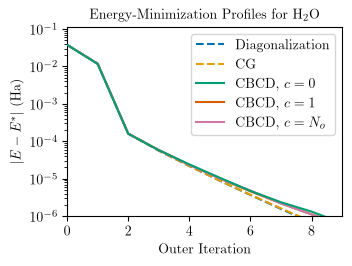

In [5]:
# Diagonalization Iter plot

fig, ax = plt.subplots()


def chem_to_latex(formula):
    return r"$\mathrm{" + re.sub(r"(\d+)", r"_{\1}", formula) + r"}$"


plt.yscale("log")
ax.set_ylabel(r"$|E - E^*|$ (Ha)")
ax.set_xlabel(r"Outer Iteration")
ax.set_title(rf"Energy-Minimization Profiles for {chem_to_latex(molecule)}")
ax.set_ylim(
    [1e-6, (prof_scf[0] - e_pyscf) * 3]
)  # extra headroom so the legend clears the curves
ax.set_xlim(
    [
        0,
        np.min(
            np.array(
                [
                    len(prof_scf),
                    len(prof_scf_cg),
                    len(prof_scf_cbcd_0),
                    len(prof_scf_cbcd_1),
                    # len(prof_opt_cbcd_2),
                    len(prof_scf_cbcd_ncols),
                ]
            )
        ),
    ]
)

plt.plot(prof_scf - e_pyscf, label="Diagonalization", color=SERIES_COLOR["Diagonalization"], linestyle="--")
plt.plot(prof_scf_cg - e_pyscf, label="CG", color=SERIES_COLOR["CG"], linestyle="--")


plt.plot(
    prof_scf_cbcd_0 - e_pyscf,
    label=r"CBCD, $c=0$",
    color=SERIES_COLOR["CBCD c=0"],
    zorder=3,
)  
plt.plot(
    prof_scf_cbcd_1 - e_pyscf,
    label=r"CBCD, $c=1$",
    color=SERIES_COLOR["CBCD c=1"],
    zorder=2,
)

plt.plot(
    prof_scf_cbcd_ncols - e_pyscf,
    label=r"CBCD, $c=N_o$",
    color=SERIES_COLOR["CBCD c=N"],
)



# drawn on top of c=1

# plt.plot(
#     prof_scf_cbcd_2 - e_pyscf, label=r"CBCD, $c=2$", color=SERIES_COLOR["CBCD c=2"]
# )
ax.legend(loc="upper right")

plt.savefig(f"{out_dir}/scf_profiles.png", dpi=300)
plt.savefig(f"{out_dir}/scf_profiles.pdf")

plt.show()

In [ ]:
from pathlib import Path

# Walk up from the notebook's cwd to the repo root (the dir containing manuscript/),
# so this works regardless of where the kernel was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ref_data").is_dir())
FIGDIR = ROOT.parent / "manuscript" / "new_figures"

fig.savefig(FIGDIR / "scf_profiles.pdf", bbox_inches="tight")
fig.savefig(FIGDIR / "scf_profiles.png", dpi=300, bbox_inches="tight")
print("wrote to", FIGDIR)

wrote to /Users/nilay/Library/CloudStorage/OneDrive-Personnel/Documents/Cornell/ManOpt/Code/Energies/manuscript/new_figures


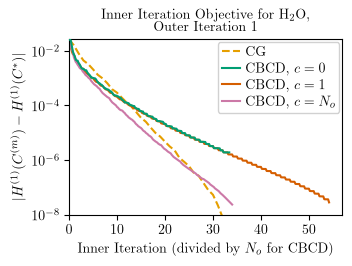

In [7]:
first_cg = prof_opt_cg[0]
first_cbcd0 = prof_opt_cbcd_0[0]
first_cbcd1 = prof_opt_cbcd_1[0]
# first_cbcd2 = prof_opt_cbcd_2[0]
first_cbcd_ncols = prof_opt_cbcd_ncols[0]

ref_e = np.min(
    [
        np.min(first_cg),
        np.min(first_cbcd0),
        np.min(first_cbcd1),
        # np.min(first_cbcd2),
        np.min(first_cbcd_ncols),
    ]
)


ne_factor = 1 / np.shape(mat)[1]
fig, ax = plt.subplots()


plt.yscale("log")
ax.set_ylabel(r"$|H^{(1)}(C^{(m)}) - H^{(1)}(C^*)|$")
ax.set_xlabel(r"Inner Iteration (divided by $N_o$ for CBCD)")
ax.set_title(
    rf"Inner Iteration Objective for {chem_to_latex(molecule)},"
    + "\n"
    + r"Outer Iteration 1"
)

ax.plot(
    np.arange(len(first_cg)),
    first_cg - ref_e,
    label="CG",
    color=SERIES_COLOR["CG"],
    linestyle="--",
)


ax.plot(
    np.arange(len(first_cbcd0)) * ne_factor,
    first_cbcd0 - ref_e,
    label=r"CBCD, $c=0$",
    color=SERIES_COLOR["CBCD c=0"],
    zorder=3,
) 

ax.plot(
    np.arange(len(first_cbcd1)) * ne_factor,
    first_cbcd1 - ref_e,
    label=r"CBCD, $c=1$",
    color=SERIES_COLOR["CBCD c=1"],
    zorder=2,
)


ax.plot(
    np.arange(len(first_cbcd_ncols)) * ne_factor,
    first_cbcd_ncols - ref_e,
    label=r"CBCD, $c=N_o$",
    color=SERIES_COLOR["CBCD c=N"],
)


 # drawn on top of c=1
# ax.plot(
#     np.arange(len(first_cbcd2)) * ne_factor,
#     first_cbcd2 - ref_e,
#     label=r"CBCD, $c=2$",
#     color=SERIES_COLOR["CBCD c=2"],
# )
# Compact legend tucked into the top-right corner (tight padding, small footprint,
# semi-opaque frame so a brushing curve stays readable).
ax.legend(
    loc="upper right",
    borderaxespad=0.2,
    borderpad=0.3,
    labelspacing=0.3,
    handlelength=1.3,
    handletextpad=0.4,
    framealpha=0.9,
)
ax.set_xlim(left=0)  # start at iteration 0
ax.set_ylim(1e-8, first_cg[0] - ref_e)  # tight top so the lines start from the top edge

plt.savefig(f"{out_dir}/first_iter_profile.png", dpi=300)
plt.savefig(f"{out_dir}/first_iter_profile.pdf")

plt.show()

In [ ]:
from pathlib import Path

# Walk up from the notebook's cwd to the repo root (the dir containing manuscript/),
# so this works regardless of where the kernel was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ref_data").is_dir())
FIGDIR = ROOT.parent / "manuscript" / "new_figures"

fig.savefig(FIGDIR / "first_iter_profile.pdf", bbox_inches="tight")
fig.savefig(FIGDIR / "first_iter_profile.png", dpi=300, bbox_inches="tight")
print("wrote to", FIGDIR)

wrote to /Users/nilay/Library/CloudStorage/OneDrive-Personnel/Documents/Cornell/ManOpt/Code/Energies/manuscript/new_figures


/var/folders/w2/_d02b3vn4cj8cgsjwsp2yxv80000gn/T/ipykernel_85186/2599299108.py:81: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  plt.savefig(f"{out_dir}/all_profiles.png", dpi=300)
/var/folders/w2/_d02b3vn4cj8cgsjwsp2yxv80000gn/T/ipykernel_85186/2599299108.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  plt.savefig(f"{out_dir}/all_profiles.pdf")
/var/folders/w2/_d02b3vn4cj8cgsjwsp2yxv80000gn/T/ipykernel_85186/2599299108.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  plt.savefig(f"{out_dir}/all_profiles.pdf")
/Users/nilay/Library/CloudStorage/OneDrive-Personnel/Documents/Cornell/ManOpt/Code/Energies/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not a

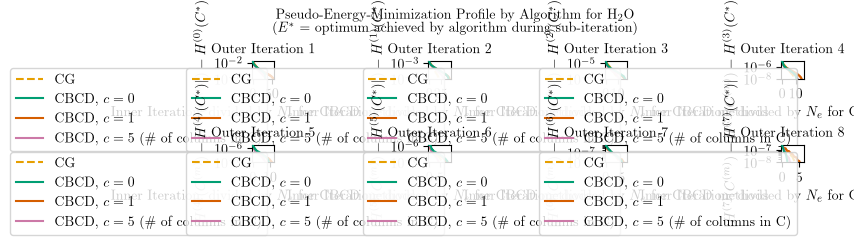

In [9]:
iters = len(prof_opt_cg)

# Full-width (figure*) plot: size to \textwidth so 10 pt text renders 1:1.
fig, axs = plt.subplots(
    2, iters // 2, figsize=(PRB_TEXT_WIDTH, PRB_TEXT_WIDTH * 8 / 28)
)

for i in range(2):
    for j in range(iters // 2):
        curr_num = (iters // 2) * i + j

        first_cg = prof_opt_cg[curr_num]
        first_cbcd0 = prof_opt_cbcd_0[curr_num]
        first_cbcd1 = prof_opt_cbcd_1[curr_num]
        # first_cbcd2 = prof_opt_cbcd_2[curr_num]
        first_cbcd_ncols = prof_opt_cbcd_ncols[curr_num]

        ne_factor = 1 / mat.shape[1]
        ax = axs[i, j]

        top_num = np.max(
            [
                np.max(first_cg[:-1] - np.min(first_cg)),
                np.max(first_cbcd0[:-1] - np.min(first_cbcd0)),
                np.max(first_cbcd1[:-1] - np.min(first_cbcd1)),
                # np.max(first_cbcd2[:-1] - np.min(first_cbcd2)),
                np.max(first_cbcd_ncols[:-1] - np.min(first_cbcd_ncols)),
            ]
        )

        ax.set_yscale("log")
        ax.set_ylabel(rf"$|H^{{({curr_num})}}(C^{{(m)}}) - H^{{({curr_num})}}(C^*)|$")
        ax.set_ylim([1e-8, top_num])
        ax.set_xlabel(r"Inner Iteration, divided by $N_e$ for CBCD methods")
        ax.set_title(rf"Outer Iteration {curr_num + 1}")

        ax.plot(
            np.arange(len(first_cg) - 1),
            first_cg[:-1] - np.min(first_cg),
            label="CG",
            color=SERIES_COLOR["CG"],
            linestyle="--",
        )

        ax.plot(
            np.arange(len(first_cbcd0) - 1) * ne_factor,
            first_cbcd0[:-1] - np.min(first_cbcd0),
            label=r"CBCD, $c=0$",
            color=SERIES_COLOR["CBCD c=0"],
            zorder=3,
        )


        ax.plot(
            np.arange(len(first_cbcd1) - 1) * ne_factor,
            first_cbcd1[:-1] - np.min(first_cbcd1),
            label=r"CBCD, $c=1$",
            color=SERIES_COLOR["CBCD c=1"],
            zorder=2,
        )
          # drawn on top of c=1
        # ax.plot(
        #     np.arange(len(first_cbcd2) - 1) * ne_factor,
        #     first_cbcd2[:-1] - np.min(first_cbcd2),
        #     label=r"CBCD, $c=2$",
        #     color=SERIES_COLOR["CBCD c=2"],
        # )
        ax.plot(
            np.arange(len(first_cbcd_ncols) - 1) * ne_factor,
            first_cbcd_ncols[:-1] - np.min(first_cbcd_ncols),
            label=rf"CBCD, $c={mat.shape[1]}$ (\# of columns in C)",
            color=SERIES_COLOR["CBCD c=N"],
        )
        ax.legend(loc="upper right")

fig.suptitle(
    rf"Pseudo-Energy-Minimization Profile by Algorithm for {chem_to_latex(molecule)}"
    + "\n"
    + r"($E^*$ = optimum achieved by algorithm during sub-iteration)"
)
plt.savefig(f"{out_dir}/all_profiles.png", dpi=300)
plt.savefig(f"{out_dir}/all_profiles.pdf")

plt.show()


# PROFILE LOOKS DIFFERENT BECAUSE DIFFERENT INITIAL CONDITIONS

In [10]:
print("CG inner iterations:", sum(len(prof) for prof in prof_opt_cg))
print("CBCD, c = N_o inner iterations:", sum(len(prof) for prof in prof_opt_cbcd_ncols))

CG inner iterations: 114
CBCD, c = N_o inner iterations: 583
